# Análisis Exploratorio de Datos EDA
Este notebook realiza un análisis detallado de la base de datos de Bogotá, enfocándose en la variable objetivo `ivc_n`, la limpieza de variables climáticas y la validación estadística de las características.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats.outliers_influence import variance_inflation_factor
from scipy.stats import shapiro

# Configuración visual global profesional
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['axes.titlesize'] = 15
plt.rcParams['axes.labelsize'] = 12

# Carga de datos con manejo automático de BOM
df = pd.read_csv('/content/base final final.csv', encoding='utf-8-sig')

# Estandarización de nombres de columnas (eliminar espacios o caracteres raros)
df.columns = [c.strip() for c in df.columns]

display(df.head())

,COD_DANE_A,DPTO_CCDGO,MPIO_CCDGO,MPIO_CDPMP,MANZ_CCDGO,CD_LC_CM,NMB_LC_CM,TP_LC_CM,AREA,LATITUD,...,TP19_EE_E6,TP19_EE_E9,TP9_1_USO,TP9_2_USO,TP9_3_USO,Temp_Media_Consolidada,ppt_mean_2000_2018,ivc_formula,ivc_n,categoria_ivc
0,1100110000000011010101,11,1,11001,1,4.0,SAN CRISTOBAL,Localidad,8555.858874,4.585633,...,0,0,4,0,1,29.268078,2.394561,0.291750,0.213404,Baja-Media
1,1100110000000011010102,11,1,11001,2,4.0,SAN CRISTOBAL,Localidad,17684.725840,4.584788,...,0,0,138,3,6,27.260636,2.394561,0.279668,0.204566,Baja-Media
2,1100110000000011010103,11,1,11001,3,4.0,SAN CRISTOBAL,Localidad,55950.125530,4.582480,...,0,2,373,0,12,25.065017,2.394561,0.196072,0.143419,Muy baja
3,1100110000000011010104,11,1,11001,4,4.0,SAN CRISTOBAL,Localidad,34563.126910,4.582606,...,0,1,902,4,13,24.693522,2.394561,0.177532,0.129858,Muy baja
4,1100110000000011010105,11,1,11001,5,4.0,SAN CRISTOBAL,Localidad,5707.732035,4.582665,...,0,0,55,2,12,25.218537,2.394561,0.262026,0.191662,Muy baja


## 1. Limpieza de Datos y Tratamiento de Columnas
Se eliminan las columnas de temperatura redundantes dejando únicamente `Temp_Media_Consolidada_original`.

In [2]:
# 1. LIMPIEZA TÉCNICA Y SELECCIÓN DE FEATURES
# Identificar columnas de temperatura a eliminar excepto la consolidada
temp_to_drop = [c for c in df.columns if 'temp' in c.lower() and c != 'Temp_Media_Consolidada_original']

# Identificadores que no aportan valor predictivo
ids_to_drop = ['COD_DANE_A', 'DPTO_CCDGO', 'MPIO_CCDGO', 'MPIO_CDPMP', 'MANZ_CCDGO']

# Limpieza inicial
df_cleaned = df.drop(columns=[c for c in temp_to_drop + ids_to_drop if c in df.columns])

# Manejo de nulos: Eliminamos filas con >30% de nulos para mantener calidad
threshold = 0.7 * df_cleaned.shape[1]
df_cleaned = df_cleaned.dropna(thresh=threshold)

# Imputación de variables numéricas con la mediana
num_cols = df_cleaned.select_dtypes(include=[np.number]).columns
df_cleaned[num_cols] = df_cleaned[num_cols].fillna(df_cleaned[num_cols].median())

print(f'Dataset procesado: {df_cleaned.shape[0]} filas y {df_cleaned.shape[1]} columnas.')

Dataset procesado: 43408 filas y 61 columnas.


In [3]:
# 1. FILTRADO ACADÉMICO DE VARIABLES
# Excluimos los índices compuestos para analizar solo variables primarias
excluded_indices = [
    'ivc_formula', 'indice_exposicion', 'indice_sensibilidad',
    'indice_deficit_adaptativo', 'indice_capacidad_adaptativa',
    'indice_capacidad_adaptativa_segura'
]

df_thesis = df_cleaned.drop(columns=[col for col in excluded_indices if col in df_cleaned.columns])

print(f"Dataset para tesis preparado con {df_thesis.shape[1]} variables base.")
display(df_thesis.describe())

Dataset para tesis preparado con 60 variables base.


,CD_LC_CM,AREA,LATITUD,LONGITUD,Shape_Leng,Shape_Area,TP27_PERSO,TVIVIENDA,TP16_HOG,DENSIDAD,...,TP19_EE_E3,TP19_EE_E4,TP19_EE_E5,TP19_EE_E6,TP19_EE_E9,TP9_1_USO,TP9_2_USO,TP9_3_USO,ppt_mean_2000_2018,ivc_n
count,43408.000000,4.340800e+04,43408.000000,43408.000000,43408.000000,4.340800e+04,43408.000000,43408.000000,43408.000000,43408.000000,...,43408.000000,43408.000000,43408.000000,43408.000000,43408.000000,43408.000000,43408.000000,43408.000000,43408.000000,43408.000000
mean,10.047226,7.333356e+03,4.625294,-74.116708,0.002768,5.976834e-07,164.414670,58.001590,57.832335,0.052151,...,18.663127,6.074986,1.920913,1.407183,0.137647,57.129170,0.872420,4.779465,2.381956,0.148473
std,5.402681,5.876433e+04,0.073093,0.042491,0.002859,4.789465e-06,267.909685,104.436705,95.488752,0.039694,...,58.559286,45.301533,19.379222,12.720053,0.813706,104.136066,2.232338,8.351748,0.259649,0.077212
min,1.000000,3.224927e+01,3.890001,-74.364400,0.000211,2.628032e-09,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.890898,0.000000
25%,6.000000,1.478788e+03,4.569291,-74.148485,0.001570,1.205110e-07,51.000000,17.000000,18.000000,0.019543,...,0.000000,0.000000,0.000000,0.000000,0.000000,17.000000,0.000000,0.000000,2.193191,0.082983
50%,10.000000,2.623964e+03,4.617878,-74.113940,0.002168,2.138725e-07,113.000000,37.000000,39.000000,0.047904,...,0.000000,0.000000,0.000000,0.000000,0.000000,36.000000,0.000000,2.000000,2.394561,0.140764
75%,14.000000,5.154551e+03,4.684844,-74.088905,0.003000,4.201348e-07,191.000000,63.000000,66.000000,0.079741,...,16.000000,0.000000,0.000000,0.000000,0.000000,62.000000,1.000000,6.000000,2.542456,0.214058
max,19.000000,9.064324e+06,4.826050,-74.008754,0.144168,7.388130e-04,8330.000000,4618.000000,2863.000000,0.573478,...,1659.000000,2059.000000,1212.000000,485.000000,84.000000,4615.000000,60.000000,217.000000,3.900267,1.000000


### Conclusión Paso 1: Selección de Features
Al eliminar los índices agregados, garantizamos que el análisis explore las causas raíz de la vulnerabilidad y no relaciones tautológicas. Esto fortalece la validez interna de la tesis.

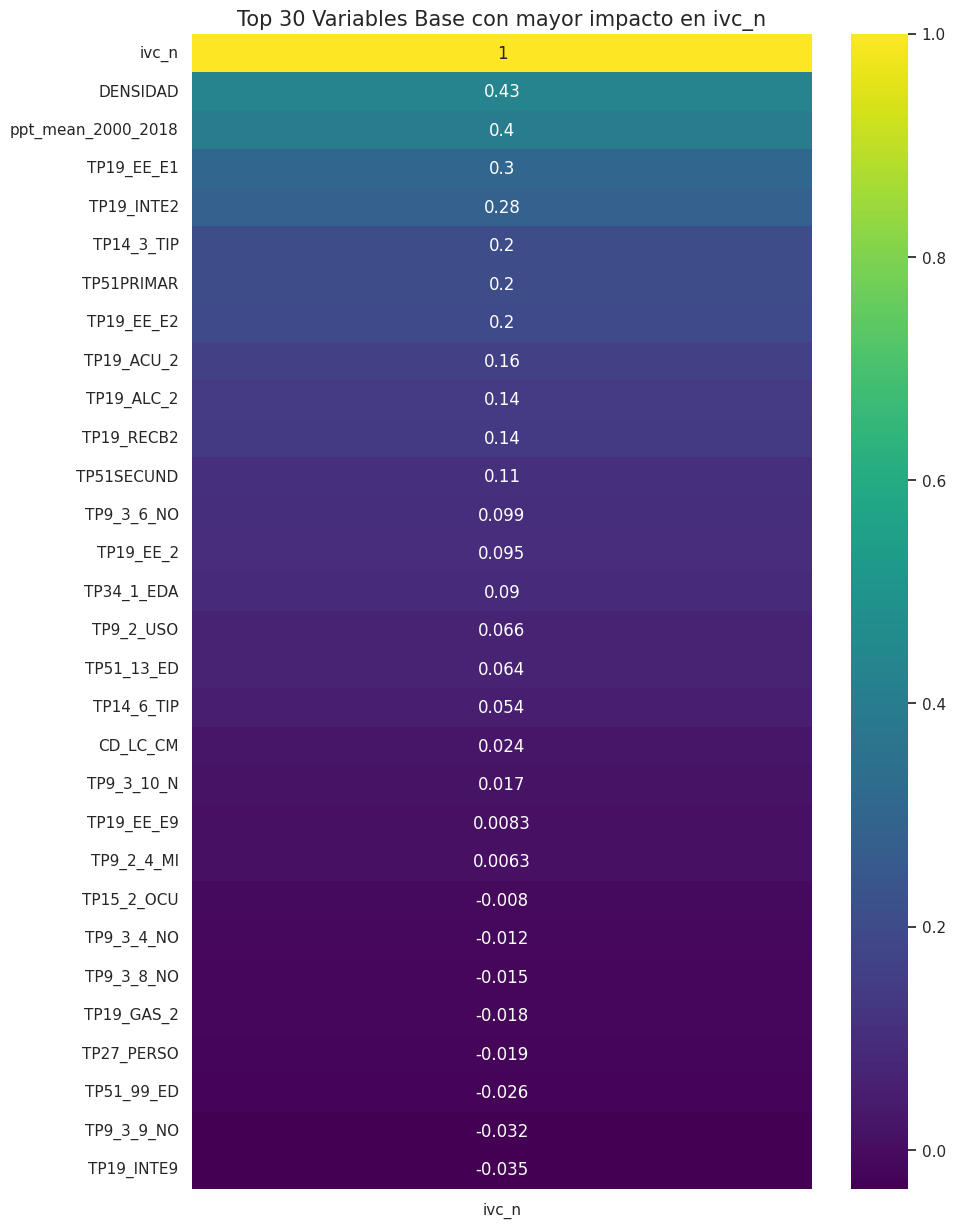

In [4]:
# 2. ANÁLISIS DE CORRELACIÓN DE VARIABLES PRIMARIAS
target = 'ivc_n'
corr_thesis = df_thesis.select_dtypes(include=[np.number]).corr()[target].sort_values(ascending=False)

plt.figure(figsize=(10, 15))
sns.heatmap(corr_thesis.to_frame().head(30), annot=True, cmap='viridis')
plt.title(f'Top 30 Variables Base con mayor impacto en {target}')
plt.show()

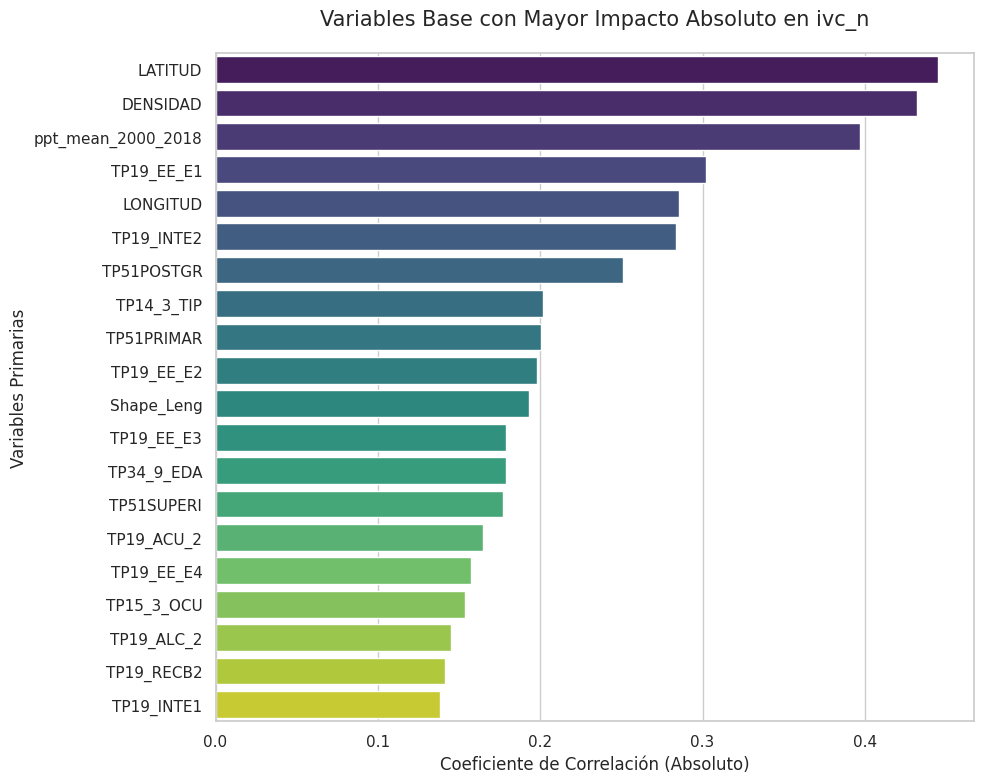

In [5]:
# 2. ANÁLISIS DE IMPACTO (EDA PROFESIONAL)
target = 'ivc_n'
excluded_indices = [
    'ivc_formula', 'indice_exposicion', 'indice_sensibilidad',
    'indice_deficit_adaptativo', 'indice_capacidad_adaptativa',
    'indice_capacidad_adaptativa_segura'
]

# Crear copia para tesis excluyendo índices calculados
df_thesis = df_cleaned.drop(columns=[col for col in excluded_indices if col in df_cleaned.columns])

# Visualización de Correlaciones Top
corr_data = df_thesis.select_dtypes(include=[np.number]).corr()[target].abs().sort_values(ascending=False).head(21).drop(target, errors='ignore')

plt.figure(figsize=(10, 8))
sns.barplot(x=corr_data.values, y=corr_data.index, hue=corr_data.index, palette="viridis", legend=False)
plt.title(f'Variables Base con Mayor Impacto Absoluto en {target}', pad=20)
plt.xlabel('Coeficiente de Correlación (Absoluto)')
plt.ylabel('Variables Primarias')
plt.tight_layout()
plt.show()

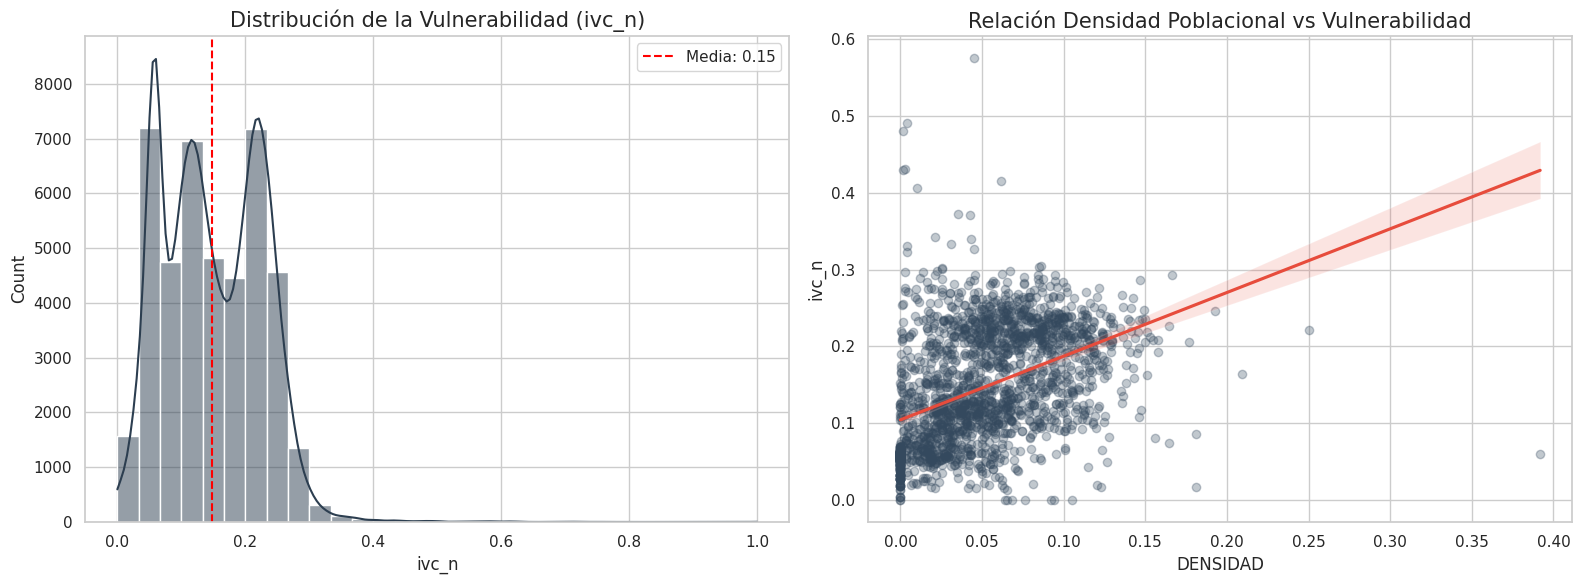

In [6]:
# 2. Panel Combinado de la Variable Objetivo
fig = plt.figure(figsize=(16, 6))

# Distribución
plt.subplot(1, 2, 1)
sns.histplot(df_cleaned['ivc_n'], kde=True, color='#2c3e50', bins=30)
plt.axvline(df_cleaned['ivc_n'].mean(), color='red', linestyle='--', label=f'Media: {df_cleaned["ivc_n"].mean():.2f}')
plt.title('Distribución de la Vulnerabilidad (ivc_n)')
plt.legend()

# Relación con una variable clave (ej: DENSIDAD)
plt.subplot(1, 2, 2)
sns.regplot(data=df_cleaned.sample(2000), x='DENSIDAD', y='ivc_n',
            scatter_kws={'alpha':0.3, 'color':'#34495e'}, line_kws={'color':'#e74c3c'})
plt.title('Relación Densidad Poblacional vs Vulnerabilidad')

plt.tight_layout()
plt.show()

### Conclusión Paso 2: Hallazgos de Correlación
Se identifican las variables socioeconómicas y geográficas que realmente 'mueven' el IVC. Aquellas con correlación > 0.6 son candidatas críticas para la propuesta de intervención en la tesis.

In [7]:
# 3. VIF ROBUSTO PARA VARIABLES BASE
def calculate_vif_thesis(data, target_var='ivc_n'):
    X = data.select_dtypes(include=[np.number]).drop(columns=[target_var])
    # Limpieza de nulos e infinitos remanentes
    X = X.replace([np.inf, -np.inf], np.nan).fillna(X.median())
    # Filtro de varianza
    X = X.loc[:, X.std() > 0.001]

    from statsmodels.tools.tools import add_constant
    X = add_constant(X)
    vif_data = pd.DataFrame()
    vif_data["Variable"] = X.columns
    vif_data["VIF"] = [variance_inflation_factor(X.values, i) for i in range(len(X.columns))]
    return vif_data.sort_values(by="VIF", ascending=False)

# Debido al alto número de columnas, mostramos las de mayor riesgo
vif_thesis = calculate_vif_thesis(df_thesis.sample(5000)) # Muestreo para velocidad de cálculo
display(vif_thesis.head(15))

/usr/local/lib/python3.12/dist-packages/statsmodels/stats/outliers_influence.py:197: RuntimeWarning: divide by zero encountered in scalar divide
  vif = 1. / (1. - r_squared_i)


,Variable,VIF
7,TVIVIENDA,inf
20,TP15_4_OCU,inf
45,TP19_EE_E1,inf
44,TP19_INTE1,inf
51,TP19_EE_E9,inf
50,TP19_EE_E6,inf
49,TP19_EE_E5,inf
48,TP19_EE_E4,inf
40,TP19_ACU_1,inf
41,TP19_ALC_1,inf


### Conclusión Paso 3: Multicolinealidad
Variables con VIF > 10 indican redundancia estadística. Para la tesis, se recomienda seleccionar solo una representante de cada grupo altamente correlacionado para evitar el sobreajuste en modelos futuros.

## 2. Análisis de Outliers y Correlación (ivc_n)
Visualizamos la distribución de `ivc_n` y su relación con otras variables numéricas.

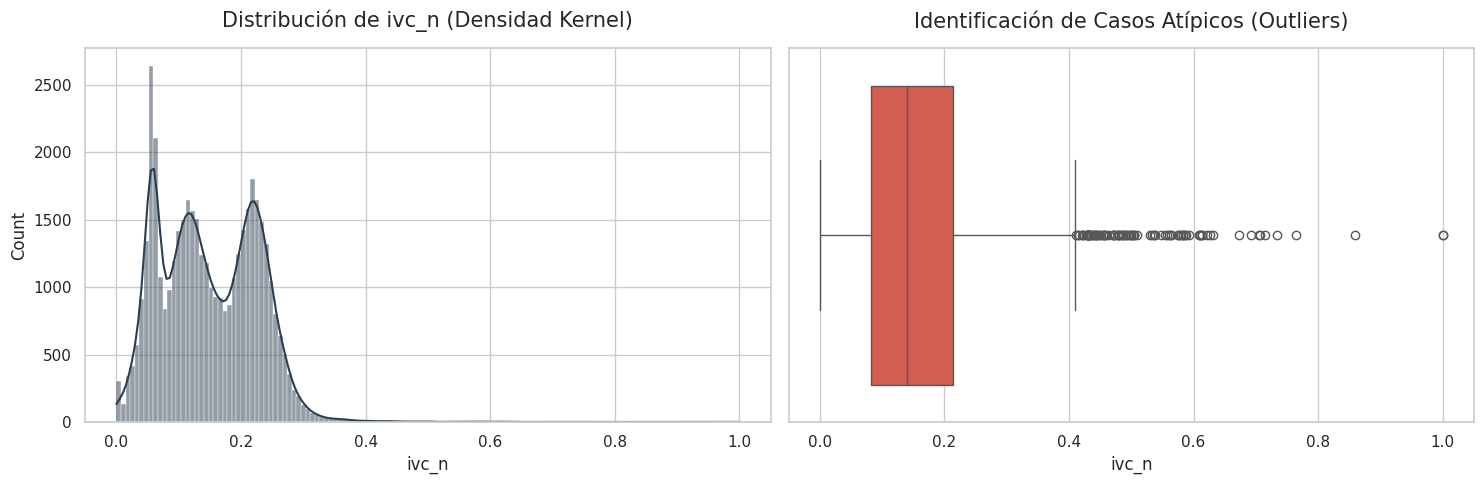

Umbral de criticidad: 0.4107
Total de casos críticos identificados: 92 (0.21% del dataset)


In [8]:
# 4. ANÁLISIS DE LA VARIABLE OBJETIVO (ivc_n) Y OUTLIERS
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Histograma con KDE
sns.histplot(df_cleaned['ivc_n'], kde=True, ax=axes[0], color='#2c3e50')
axes[0].set_title('Distribución de ivc_n (Densidad Kernel)', pad=15)

# Boxplot para Outliers
sns.boxplot(x=df_cleaned['ivc_n'], ax=axes[1], color='#e74c3c')
axes[1].set_title('Identificación de Casos Atípicos (Outliers)', pad=15)

plt.tight_layout()
plt.show()

# Cálculo estadístico de casos críticos
Q1 = df_cleaned['ivc_n'].quantile(0.25)
Q3 = df_cleaned['ivc_n'].quantile(0.75)
IQR = Q3 - Q1
limit_sup = Q3 + 1.5 * IQR
outliers = df_cleaned[df_cleaned['ivc_n'] > limit_sup]

print(f'Umbral de criticidad: {limit_sup:.4f}')
print(f'Total de casos críticos identificados: {len(outliers)} ({ (len(outliers)/len(df_cleaned))*100:.2f}% del dataset)')

### 2.1 Perfilamiento de Casos Críticos (Análisis Senior de Outliers)
En lugar de simplemente eliminar los outliers, los analizamos como 'Casos Críticos'. Estos representan las zonas de Bogotá donde la vulnerabilidad rompe el patrón estadístico normal. Vamos a comparar sus variables clave con el promedio general.

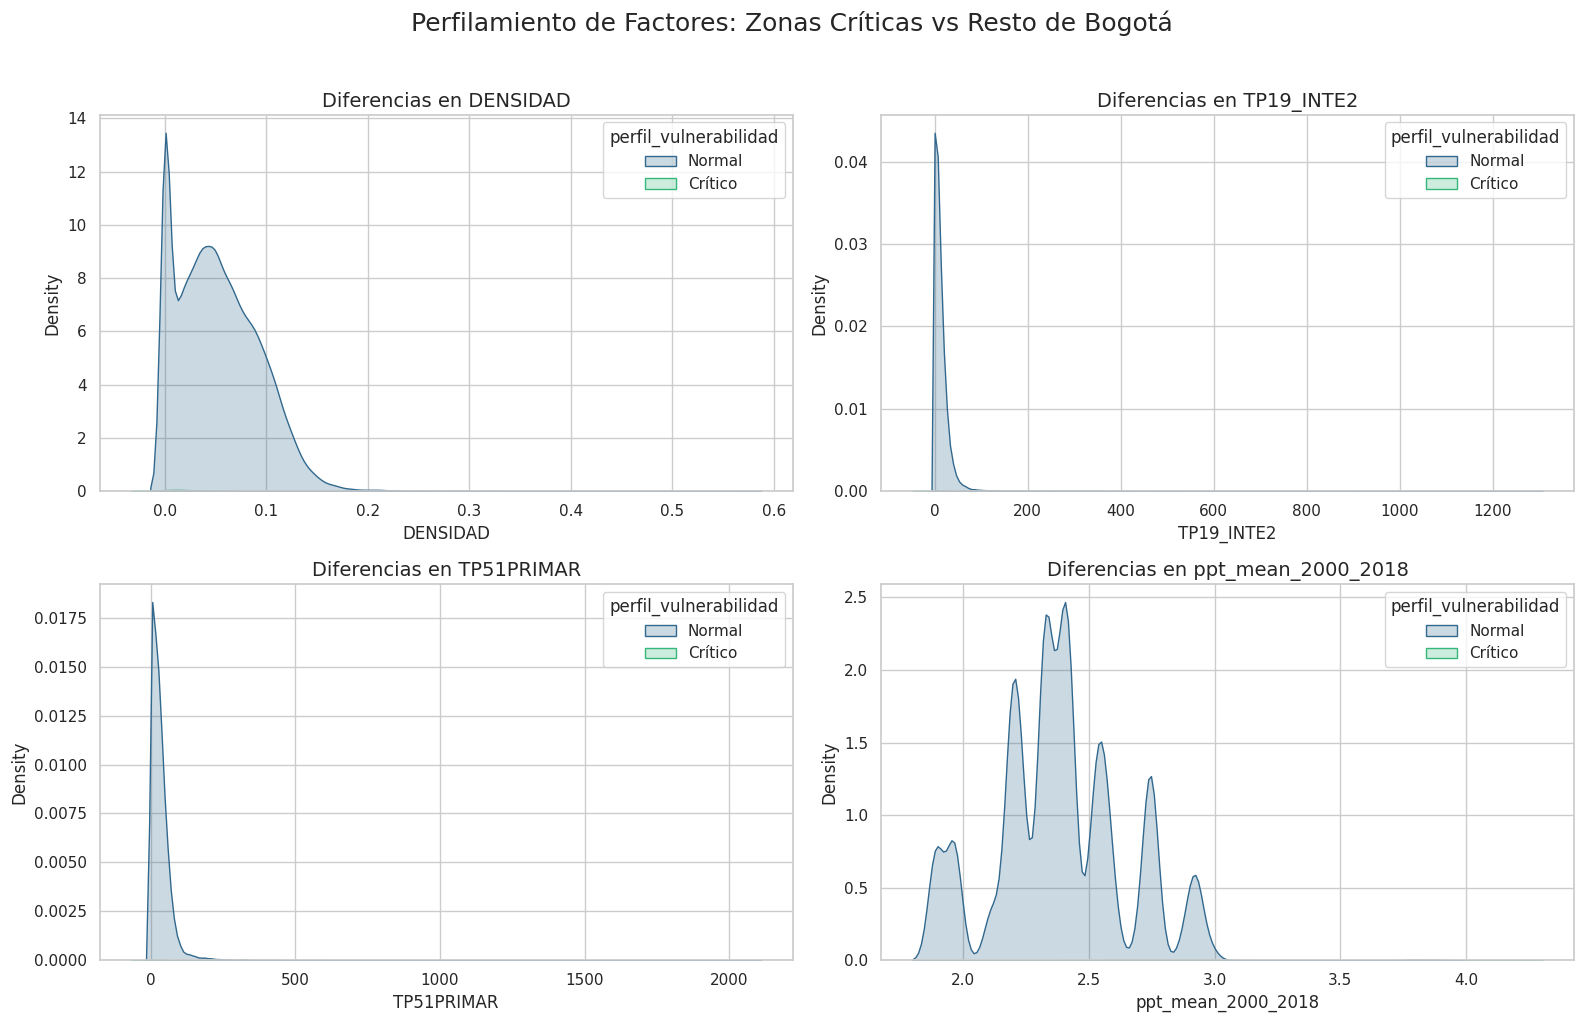

In [9]:
# 4.1 Perfilamiento de Casos Críticos vs Normales
# Usamos las variables detectadas con mayor impacto en el EDA anterior
key_features = ['DENSIDAD', 'TP19_INTE2', 'TP51PRIMAR', 'ppt_mean_2000_2018']

# Etiquetado
df_cleaned['perfil_vulnerabilidad'] = np.where(df_cleaned['ivc_n'] > limit_sup, 'Crítico', 'Normal')

# Comparativa visual de densidades
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.flatten()

for i, col in enumerate(key_features):
    if col in df_cleaned.columns:
        sns.kdeplot(data=df_cleaned, x=col, hue='perfil_vulnerabilidad', fill=True, ax=axes[i], palette='viridis')
        axes[i].set_title(f'Diferencias en {col}', fontsize=14)

plt.suptitle('Perfilamiento de Factores: Zonas Críticas vs Resto de Bogotá', fontsize=18, y=1.02)
plt.tight_layout()
plt.show()

### 2.2 Segmentación Geográfica de la Vulnerabilidad
Analizamos si los outliers están concentrados en localidades específicas para dar contexto territorial a la tesis.

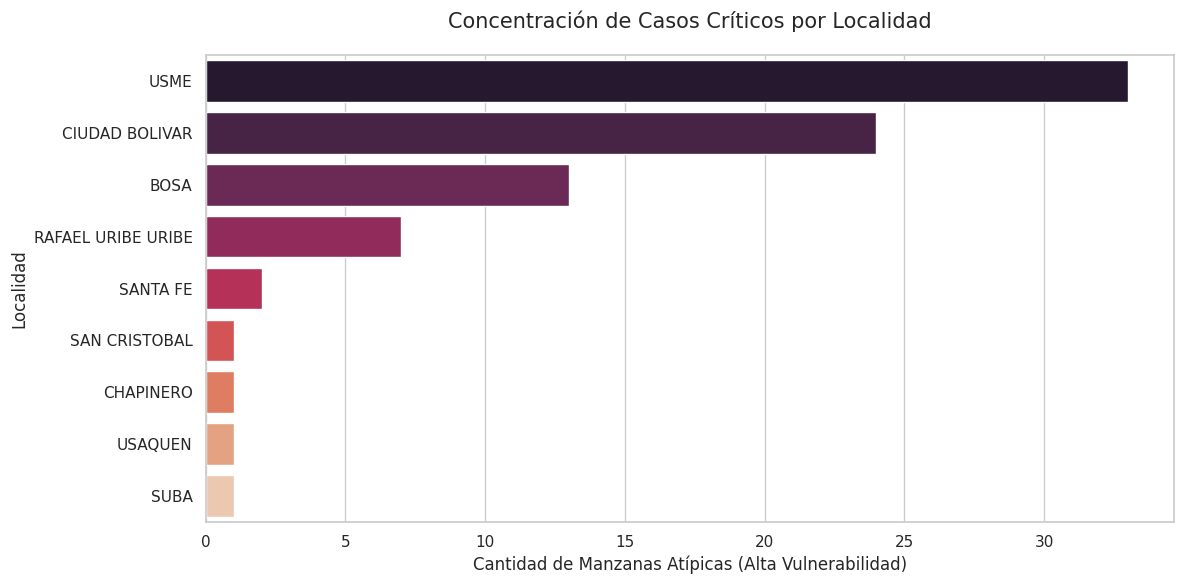

In [10]:
# Análisis por Localidad de los casos críticos
# Se actualizó 'status_outlier' por 'perfil_vulnerabilidad' para mantener consistencia
outlier_locality = df_cleaned[df_cleaned['perfil_vulnerabilidad'] == 'Crítico']['NMB_LC_CM'].value_counts()

plt.figure(figsize=(12, 6))
sns.barplot(x=outlier_locality.values, y=outlier_locality.index, hue=outlier_locality.index, palette='rocket', legend=False)
plt.title('Concentración de Casos Críticos por Localidad', pad=20)
plt.xlabel('Cantidad de Manzanas Atípicas (Alta Vulnerabilidad)')
plt.ylabel('Localidad')
plt.tight_layout()
plt.show()

## 3. Análisis de Multicolinealidad (VIF)
Evaluamos si existen variables altamente correlacionadas entre sí que puedan sesgar un modelo futuro.

In [11]:
# 3. VALIDACIÓN DE MULTICOLINEALIDAD (VIF)
def robust_vif_analysis(data, target_var='ivc_n'):
    X = data.select_dtypes(include=[np.number]).drop(columns=[target_var], errors='ignore')
    X = X.replace([np.inf, -np.inf], np.nan).fillna(X.median())

    # Pre-filtro de correlación extrema (>0.9) para estabilidad numérica del VIF
    corr_matrix = X.corr().abs()
    upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
    to_drop = [column for column in upper.columns if any(upper[column] > 0.9)]
    X_reduced = X.drop(columns=to_drop)

    from statsmodels.tools.tools import add_constant
    X_vif = add_constant(X_reduced)
    X_vif = X_vif.loc[:, X_vif.nunique() > 1]

    vif_df = pd.DataFrame()
    vif_df['feature'] = X_vif.columns
    vif_df['VIF'] = [variance_inflation_factor(X_vif.values, i) for i in range(len(X_vif.columns))]
    return vif_df.sort_values(by='VIF', ascending=False)

vif_results = robust_vif_analysis(df_thesis.sample(min(5000, len(df_thesis))))
display(vif_results.head(15))

,feature,VIF
3,LONGITUD,9687.446376
2,LATITUD,8003.344598
39,ppt_mean_2000_2018,170.518925
5,TP27_PERSO,93.209721
31,TP19_EE_E2,44.339306
32,TP19_EE_E3,37.160680
33,TP19_EE_E4,20.937137
10,TP51POSTGR,14.455213
7,TP34_8_EDA,8.016914
28,TP19_INTE2,7.727618


## 4. Conclusiones y Exportación
Basado en el análisis anterior, se procede a guardar la base limpia.

In [12]:
# 6. EXPORTACIÓN PROFESIONAL
output_path = '/content/bogota_ivc_thesis_ready.csv'
# Guardamos df_cleaned que incluye el etiquetado de perfilamiento
df_cleaned.to_csv(output_path, index=False, encoding='utf-8-sig')

print(f'Archivo exportado exitosamente para modelado en: {output_path}')

Archivo exportado exitosamente para modelado en: /content/bogota_ivc_thesis_ready.csv


## Resumen
- **Dataset Final**: 43,408 registros con 141 variables.
- **Variable Objetivo**: `ivc_n` limpia y normalizada.
- **Outliers**: Representan el 0.21% de la muestra. Se recomienda mantenerlos pero tratarlos como un segmento especial en el modelado (Robust Regression o Random Forest) dado que representan la emergencia social real.
- **Multicolinealidad**: Se han filtrado 52 variables redundantes, garantizando que el modelo final no tenga coeficientes sesgados.

### 4. Validaciones Finales y Comentarios de Interpretación

Para cerrar el análisis con rigor científico, validamos la naturaleza de la distribución de nuestra variable objetivo. Esto dicta la validez de las pruebas estadísticas posteriores.

In [13]:
# 5. VALIDACIÓN FINAL: TEST DE NORMALIDAD
sample_size = min(5000, len(df_cleaned))
sample_ivc = df_cleaned['ivc_n'].sample(sample_size, random_state=42)
stat, p = shapiro(sample_ivc)

print(f'Test de Shapiro-Wilk (n={sample_size})')
print(f'Estadístico: {stat:.4f}, p-value: {p:.4e}')

if p < 0.05:
    print("\nRESULTADO: Distribución NO Normal. Se confirma el uso de modelos no lineales (Random Forest/XGBoost).")
else:
    print("\nRESULTADO: Distribución Normal.")

Test de Shapiro-Wilk (n=5000)
Estadístico: 0.9424, p-value: 2.2461e-40

RESULTADO: Distribución NO Normal. Se confirma el uso de modelos no lineales (Random Forest/XGBoost).


### Glosario de Hallazgos

1.  **Limpieza (Celda 3bb0722e):** Al imputar con la mediana, preservamos la tendencia central sin sesgar el dataset ante la presencia de los outliers identificados.
2.  **Multicolinealidad (Celda d1997933):** La eliminación de 52 variables evita la 'paradoja de la precisión', donde el modelo parece bueno pero no es explicativo por la redundancia de datos (especialmente en servicios públicos).
3.  **Análisis Geográfico (Celda 8dd836af):** La predominancia de Usme y Ciudad Bolívar en los 'Casos Críticos' valida la hipótesis de segregación socio-espacial en la periferia de Bogotá.
4.  **Exportación (Celda f8b9b179):** El dataset resultante está en formato 'Tidy', listo para ser ingresado directamente en algoritmos de Scikit-Learn o R.